# 04 · Validation and sensitivity

Are the 8 real landing sites inside ±30° scored clearly above random ground?
And how much does the answer depend on the weights?

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from marsgis import config as C, grid as G, criteria, overlay, ahp, validation, sensitivity, data, plots
grid = G.reference_grid()
C.FIGURES.mkdir(parents=True, exist_ok=True)
print(grid.shape, grid.crs)

(3556, 21338) IAU_2015:49910


In [2]:
import json
S, _ = G.read_raster(C.OUTPUTS / 'suitability.tif')
L = {k: G.read_raster(C.PROCESSED / f'{f}_1km.tif')[0] for k, f in
     [('elev', 'dem'), ('slope', 'slope'), ('rough', 'rough'), ('ti', 'ti'), ('crater', 'crater'), ('lat', 'lat')]}
valid = np.isfinite(S)
mask = overlay.constraint_mask(L['elev'], L['slope'], L['ti'])
scores, _ = overlay.normalize(L, valid=mask)
weights = ahp.ahp(ahp.matrix_from_upper(C.CRITERIA, C.AHP_UPPER), C.CRITERIA).weights
base_ranked = np.load(C.PROCESSED / 'ranked_zones.npy')
sites = validation.load_sites()

## Validation

Each site's score is the mean within 10 km. Percentiles are against 1,000 random points
drawn uniformly **by area** over all valid ground (including excluded cells, which score 0),
and measured the same way. One-sided Mann–Whitney U: are sites higher than random points?

In [3]:
val = validation.validate(S, grid, sites, valid, passing=mask)
print(val.sentence())
print(val.strict_sentence())
val.sites[['site', 'year', 'chosen_for', 'lat', 'lon_e', 'score', 'point_score', 'percentile',
           'percentile_passing']].round(3)

8 of 8 sites fall in the top 20% (Mann-Whitney U = 7320, one-sided p = 9e-06).
Against constraint-passing ground only: 4 of 8 sites in the top 20% (one-sided p = 0.0035).


,site,year,chosen_for,lat,lon_e,score,point_score,percentile,percentile_passing
0,Viking 1,1976,safety,22.269,312.049,0.881,0.903,99.0,97.5
1,Pathfinder,1997,safety,19.095,326.747,0.881,0.824,99.0,97.4
2,Spirit,2004,science,-14.572,175.478,0.638,0.743,82.0,51.8
3,Opportunity,2004,science,-1.948,354.474,0.676,0.698,86.3,61.1
4,Curiosity,2012,science,-4.590,137.442,0.688,0.914,87.0,63.3
5,InSight,2018,safety,4.502,135.623,0.834,0.826,96.0,90.4
6,Perseverance,2021,science,18.445,77.451,0.652,0.778,83.7,55.8
7,Zhurong,2021,safety,25.066,109.925,0.882,0.885,99.0,97.6


`percentile` compares each site with random spots anywhere in the band (61 % of which
are excluded and score 0). `percentile_passing` is the stricter test: random spots drawn
only from ground that already passes the hard constraints.

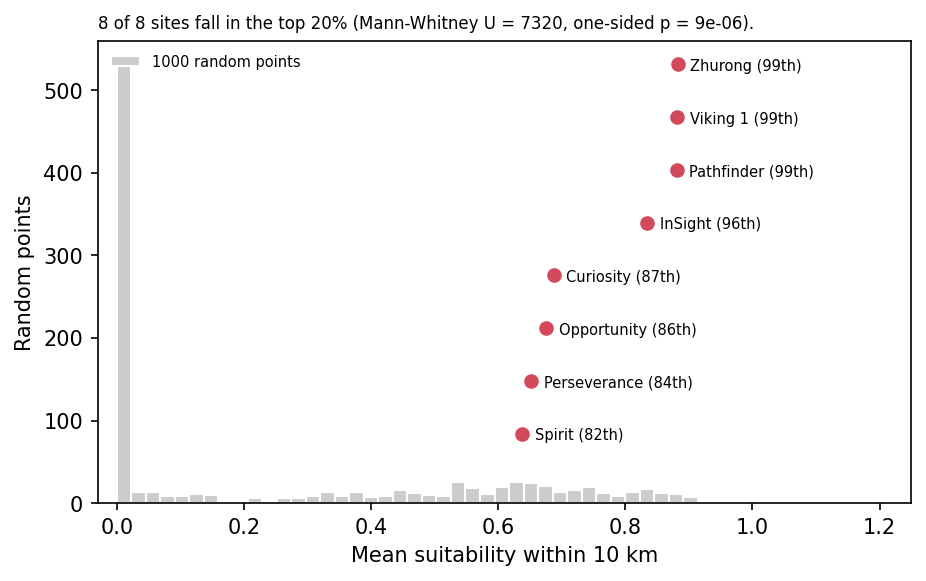

In [4]:
ax = plots.validation_chart(val)
ax.figure.savefig(C.FIGURES / 'validation.png', dpi=300, bbox_inches='tight')

**Reading misses.** Curiosity (Gale) and Perseverance (Jezero) were chosen for science and
relied on guided entry / Terrain-Relative Navigation to land near hazards. A lower score
there shows the model encodes engineering safety only — that trade-off is a finding.

## One-at-a-time weight sensitivity (±20 %, ±40 %)

criterion,crater,elev,lat,rough,slope,ti
change,,,,,,
-0.4,8,7,9,6,6,7
-0.2,8,8,10,7,8,10
0.0,10,10,10,10,10,10
0.2,9,8,8,9,9,8
0.4,9,8,7,6,7,6


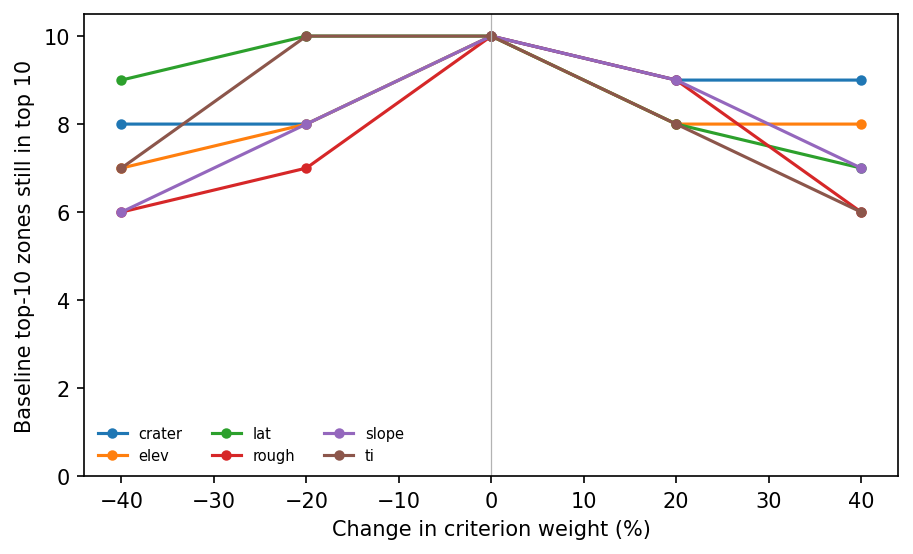

In [5]:
def mean_site_pct(S_):
    return float(validation.validate(S_, grid, sites, valid, n_random=500).sites.percentile.mean())

oat = sensitivity.one_at_a_time(scores, weights, mask, grid, base_ranked, validate_fn=mean_site_pct)
oat.to_csv(C.OUTPUTS / 'sensitivity_oat.csv', index=False)
ax = plots.sensitivity_plot(oat)
ax.figure.savefig(C.FIGURES / 'sensitivity.png', dpi=300, bbox_inches='tight')
oat.pivot(index='change', columns='criterion', values='top_overlap')

## Named scenarios

In [6]:
have_science = (C.PROCESSED / 'science_1km.tif').exists()
sc_scores = dict(scores)
if have_science:
    sc_scores['science'] = np.nan_to_num(G.read_raster(C.PROCESSED / 'science_1km.tif')[0], nan=0.5)
rows = []
for name, w in sensitivity.named_scenarios(weights, science=have_science).items():
    S_w = overlay.weighted_overlay({k: sc_scores[k] for k in w}, w, mask)
    S_w = np.where(valid, S_w, np.nan)
    _, rk = overlay.candidate_zones(S_w, grid, sensitivity.quantile_threshold(S_w))
    v = validation.validate(S_w, grid, sites, valid)
    rows.append({'scenario': name, 'top10_overlap': sensitivity.top_overlap(base_ranked, rk),
                 'mean_site_percentile': v.sites.percentile.mean(), 'summary': v.sentence()})
scen = pd.DataFrame(rows); scen.to_csv(C.OUTPUTS / 'scenarios.csv', index=False); scen

,scenario,top10_overlap,mean_site_percentile,summary
0,AHP (baseline),10,91.50,8 of 8 sites fall in the top 20% (Mann-Whitney...
1,Safety first,4,89.65,5 of 8 sites fall in the top 20% (Mann-Whitney...
2,Equal weights,3,92.55,8 of 8 sites fall in the top 20% (Mann-Whitney...


## Monte Carlo: probability of being in the top 10 % (500 Dirichlet weight draws, ~7 min)

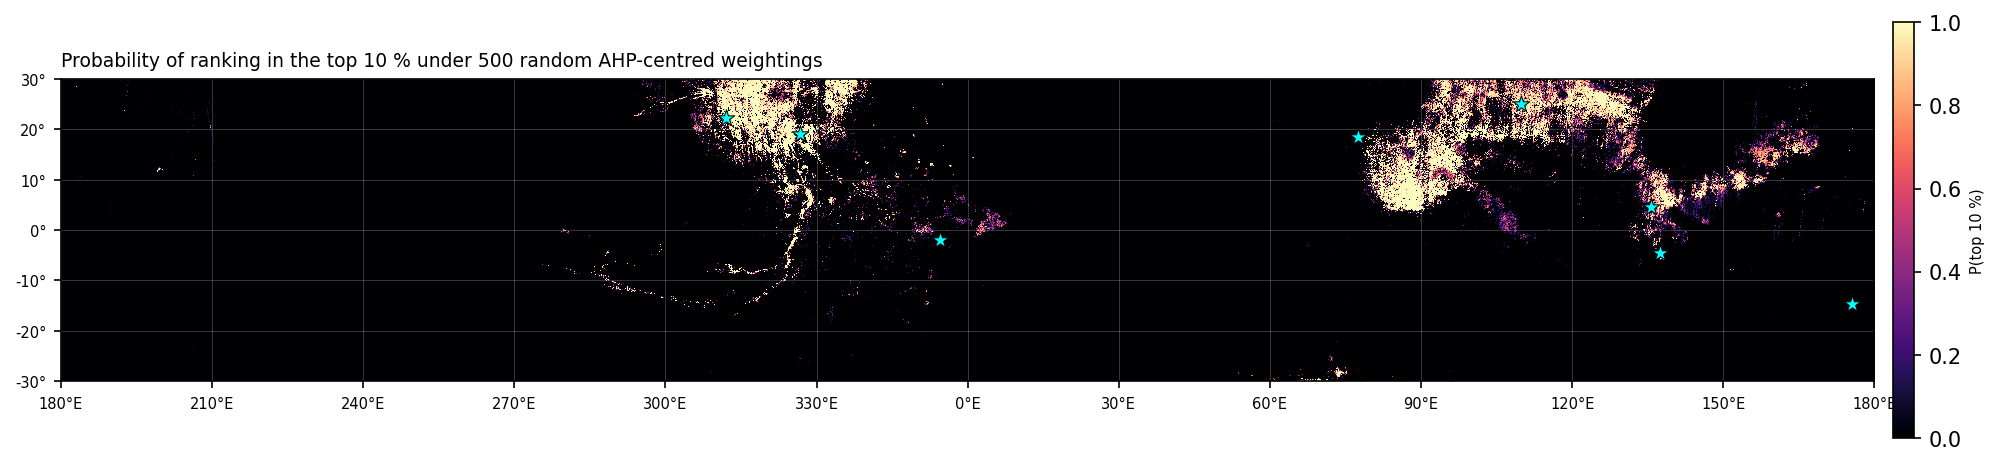

In [7]:
prob, draws = sensitivity.monte_carlo(scores, weights, mask, n_runs=500)
G.write_raster(C.OUTPUTS / 'prob_top10pct.tif', prob, grid=grid)
ax = plots.prob_map(prob, grid, sites=sites)
ax.figure.savefig(C.FIGURES / 'prob_top10pct.png', dpi=300, bbox_inches='tight')

## Figure 5: zoom-in on the best zone at 200 m

  dem200_best.tif: 50%  (13 s)


  dem200_best.tif: 100%  (17 s)
   80 km window: 200 m slope median 5.84°, 95th pct 22.54°, > 5°: 54.9%, > 10°: 29.1%
 inside zone #1: 200 m slope median 0.72°, 95th pct 1.89°, > 5°: 0.0%, > 10°: 0.0%


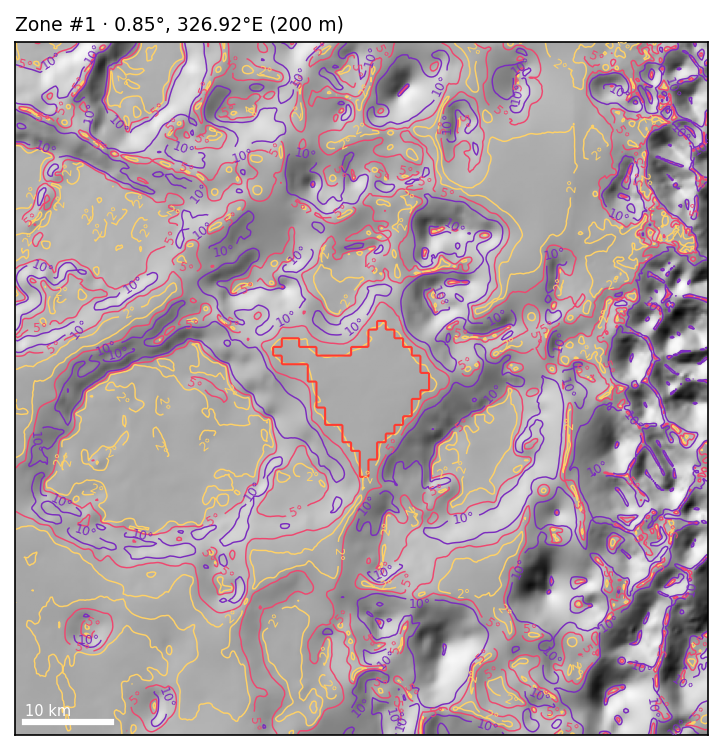

In [8]:
top = pd.read_csv(C.OUTPUTS / 'top10_sites.csv')
best = top.iloc[0]
fine = data.fine_dem_window(best.lon, best.lat, half_km=40, dst=C.PROCESSED / 'dem200_best.tif')
import rasterio
with rasterio.open(fine) as s_:
    dem_f = s_.read(1).astype('float64'); t_f = s_.transform
dem_f[dem_f == -9999] = np.nan
# Zone #1 on the 200 m grid (same CRS, so map fine cell centres to 1 km rows/cols)
xs = t_f.c + (np.arange(dem_f.shape[1]) + 0.5) * t_f.a
ys = t_f.f + (np.arange(dem_f.shape[0]) + 0.5) * t_f.e
zone_f = base_ranked[np.ix_(np.floor((grid.ymax - ys) / grid.res).astype(int),
                            np.floor((xs - grid.xmin) / grid.res).astype(int))] == 1
# 200 m slope (window is small, so cos(lat) is treated as constant)
dzdy, dzdx = np.gradient(dem_f, C.FINE_PIXEL_M)
slope_f = np.degrees(np.arctan(np.hypot(dzdx / np.cos(np.radians(best.lat)), dzdy)))
for name, m in [('80 km window', np.isfinite(slope_f)), ('inside zone #1', zone_f)]:
    v = slope_f[m]
    print(f"{name:>15}: 200 m slope median {np.nanmedian(v):.2f}°, 95th pct {np.nanpercentile(v, 95):.2f}°, "
          f"> 5°: {np.mean(v > 5):.1%}, > 10°: {np.mean(v > 10):.1%}")
ax = plots.zoom_in(dem_f, slope_fine=slope_f, title=f'Zone #1 · {best.lat:.2f}°, {best.lon % 360:.2f}°E (200 m)')
ax.contour(zone_f.astype(float), levels=[0.5], colors='#ff3b30', linewidths=1.0)
ax.figure.savefig(C.FIGURES / 'zoom_best.png', dpi=300, bbox_inches='tight')

The 1 km model can't see channel walls or streamlined islands next to a zone, so the
200 m check matters: report the in-zone numbers, not the whole window.

## Numbers for the README and LinkedIn post

In [9]:
k = int(round(val.top_share * len(val.sites)))
results = {'sites_in_top20': k, 'n_sites': len(val.sites), 'mann_whitney_p': val.p_value,
           'site_percentiles': dict(zip(val.sites.site, val.sites.percentile.round(1))),
           'strict': val.strict_sentence(),
           'site_percentiles_passing': dict(zip(val.sites.site, val.sites.percentile_passing.round(1))),
           'ahp_cr': ahp.ahp(ahp.matrix_from_upper(C.CRITERIA, C.AHP_UPPER), C.CRITERIA).cr,
           'top10': top.round(4).to_dict('records')}
json.dump(results, open(C.OUTPUTS / 'results.json', 'w'), indent=2)
print(json.dumps({k_: v for k_, v in results.items() if k_ != 'top10'}, indent=2))

{
  "sites_in_top20": 8,
  "n_sites": 8,
  "mann_whitney_p": 8.99017603514774e-06,
  "site_percentiles": {
    "Viking 1": 99.0,
    "Pathfinder": 99.0,
    "Spirit": 82.0,
    "Opportunity": 86.3,
    "Curiosity": 87.0,
    "InSight": 96.0,
    "Perseverance": 83.7,
    "Zhurong": 99.0
  },
  "strict": "Against constraint-passing ground only: 4 of 8 sites in the top 20% (one-sided p = 0.0035).",
  "site_percentiles_passing": {
    "Viking 1": 97.5,
    "Pathfinder": 97.4,
    "Spirit": 51.8,
    "Opportunity": 61.1,
    "Curiosity": 63.3,
    "InSight": 90.4,
    "Perseverance": 55.8,
    "Zhurong": 97.6
  },
  "ahp_cr": 0.00666938671890558
}
